<a href="https://colab.research.google.com/github/JFish72/CSC-349-Machine-Learning-/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task One:**
*   For this project, rather than downloading a CSV file, I imported the fetch_olivetti_faces() dataset from scikit-learn. I then printed out the total number of samples, unique subjects, the feature dimensions, and plotted a 4x5 grid of sample faces.
*   The given samples are meant to highlight the differences between each photo and give a general idea of the data and the difficulty we might have working with it.


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total samples: 400
Unique subjects: 40
Feature dimensions: 4096


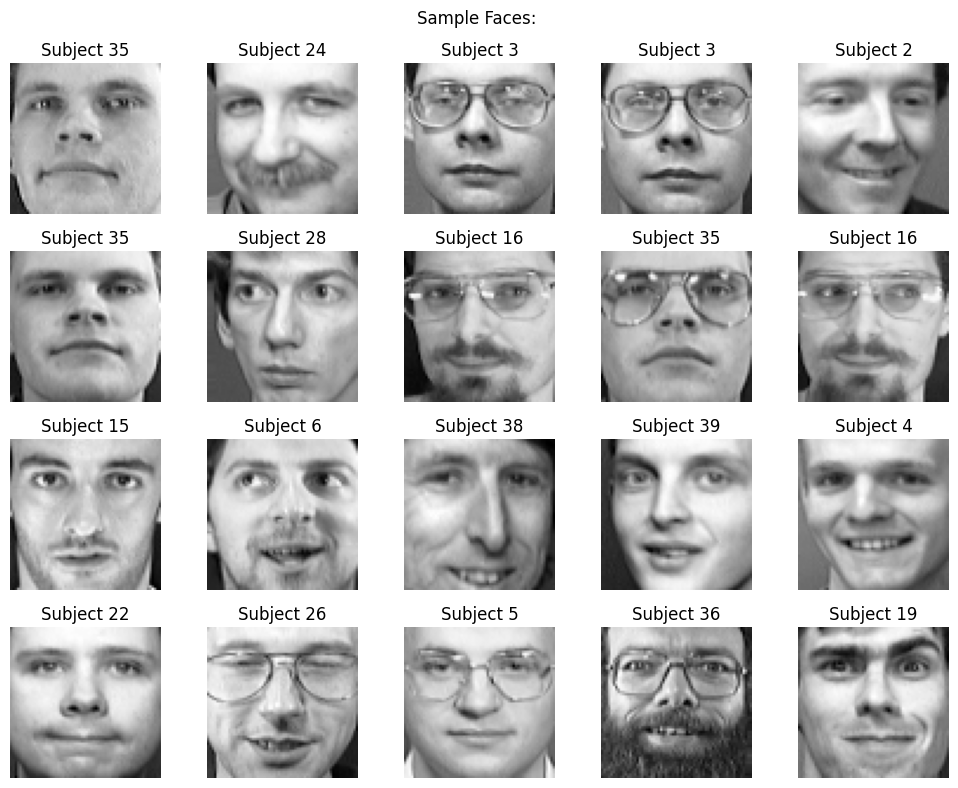

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.metrics import ConfusionMatrixDisplay

faces = fetch_olivetti_faces(shuffle = False)

X = faces.data
y = faces.target
image = faces.images

print("Total samples:", X.shape[0])
print("Unique subjects:", len(np.unique(y)))
print("Feature dimensions:", X.shape[1])

fig, axes = plt.subplots(4, 5, figsize = (10, 8))

sample_indices = np.random.choice(range(X.shape[0]), size = 20, replace = False)

for ax, idx in zip(axes.flat, sample_indices):
  ax.imshow(image[idx], cmap = 'gray')
  ax.set_title(f"Subject {y[idx]}")
  ax.axis('off')

plt.suptitle("Sample Faces: ")
plt.tight_layout()
plt.show()

**Task Two:**
*   In this task, I am using a PCA model to fit the whole dataset to show the variance captured by the principal components. Following this, I'm going to calculate the individual and cumulative explained variance to determine the minimum number of components required to preserve 90%, 95%, and 99% of the variance.   
*   Two graphs will also be created to better visualize how the variance changes as more components are introduced. Overral this demostrates how we can use PCA to reduce the large dataset's features and still preserve most of the information from the images.

90% variance: 66 components
95% variance: 123 components
99% variance: 260 components


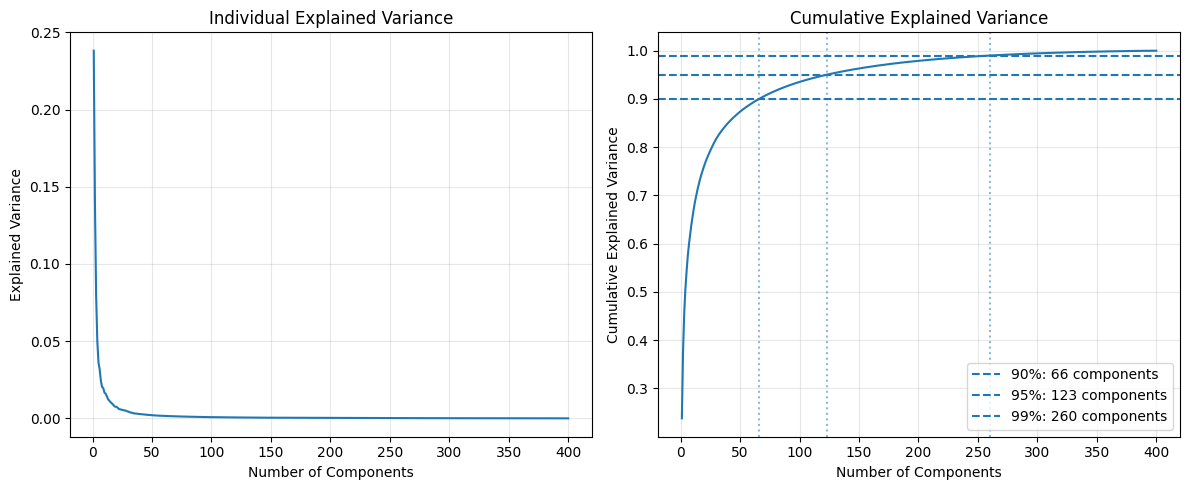

In [4]:
pca_full = PCA(svd_solver='full')
pca_full.fit(X)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

components_count = {}

for threshold in [0.9, 0.95, 0.99]:
  k = int(np.searchsorted(cumulative_variance, threshold) + 1)
  components_count[threshold] = k
  print(f'{threshold:.0%} variance: {k} components')

fig, axes = plt.subplots(1, 2, figsize = (12, 5))
axes[0].plot(np.arange(1, len(explained_variance) + 1), explained_variance)
axes[0].set(title = 'Individual Explained Variance', xlabel = 'Number of Components', ylabel = 'Explained Variance')
axes[1].plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)

for threshold, k in components_count.items():
  axes[1].axhline(threshold, linestyle = '--', label = f'{threshold:.0%}: {k} components')
  axes[1].axvline(k, linestyle = ':', alpha = 0.5)

axes[1].set(title = 'Cumulative Explained Variance', xlabel = 'Number of Components', ylabel = 'Cumulative Explained Variance')
axes[1].legend()

for ax in axes:
   ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

**Task Three:**
*   To highlight the difference in the number of PCA components retained when it comes to constructing the facial images. I have selected 5 photos and will reconstruct them at 10, 50, 100, 200, and 300 PCA components. To show their visual differnece I will compare them to their originals as well.
*   For each image, I will also show its MSE and create an MSE curve to show how the difference in PCA components affects reconstruction error.



k = 10: MSE: 0.0056
k = 50: MSE: 0.0022
k = 100: MSE: 0.0012
k = 200: MSE: 0.0005
k = 300: MSE: 0.0001


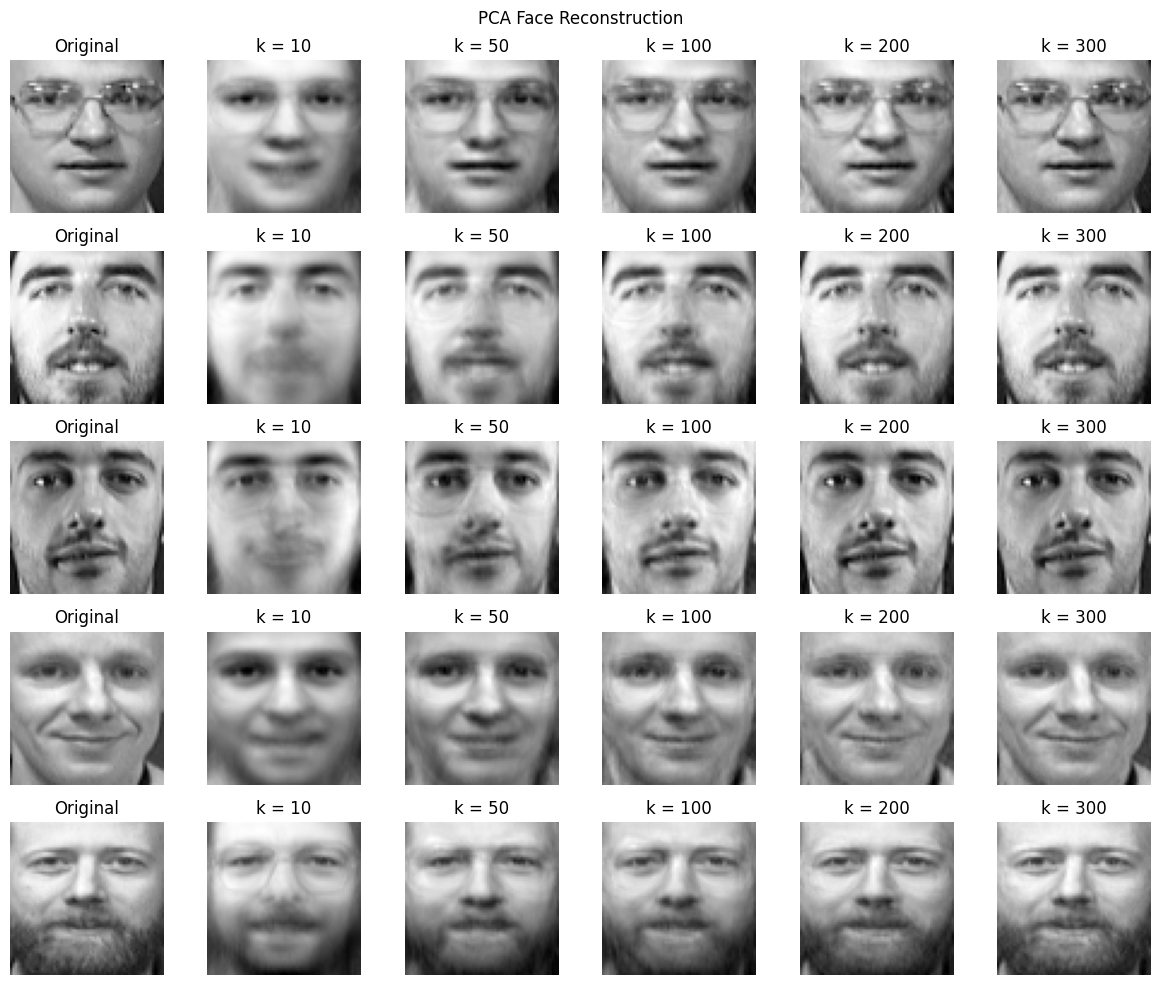

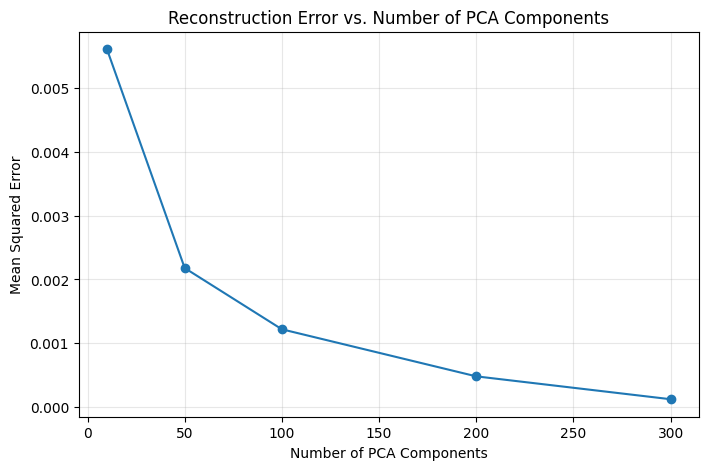

In [5]:
selected_indices = [np.where(y == s) [0][0] for s in [5, 10, 15, 20, 25]]
original_images = X[selected_indices]

k_values = [10, 50, 100, 200, 300]

projected = pca_full.transform(original_images)
reconstructed_images, mse_values = {}, []

for k in k_values:
  reconstructed = np.dot(projected[:, :k], pca_full.components_[:k]) + pca_full.mean_
  reconstructed_images[k] = reconstructed
  mse = mean_squared_error(original_images, reconstructed)
  mse_values.append(mse)
  print(f'k = {k}: MSE: {mse:.4f}')

fig, axes = plt.subplots(5, 6, figsize = (12, 10))

for i in range (5):
  axes[i, 0].imshow(original_images[i].reshape(64, 64), cmap = 'gray')
  axes[i, 0].set_title(f'Original')
  for j, k in enumerate(k_values):
    axes[i, j + 1].imshow(reconstructed_images[k][i].reshape(64, 64), cmap = 'gray')
    axes[i, j + 1].set_title(f'k = {k}')
  for ax in axes[i]: ax.axis('off')

plt.suptitle('PCA Face Reconstruction')
plt.tight_layout()
plt.show()

plt.figure(figsize = (8, 5))
plt.plot(k_values, mse_values, marker = 'o')
plt.xlabel('Number of PCA Components')
plt.ylabel('Mean Squared Error')
plt.title('Reconstruction Error vs. Number of PCA Components')
plt.grid(alpha = 0.3)
plt.show()

**Task Four:**
*   To visualize the patterns of variation PCA learns from the different faces in the dataset, I'm going to reshape the first 15 PCA component vectors into 64 by 64 grayscale images (eigenfaces). Each image will be annotated with the percentage of total variance explained by its components.

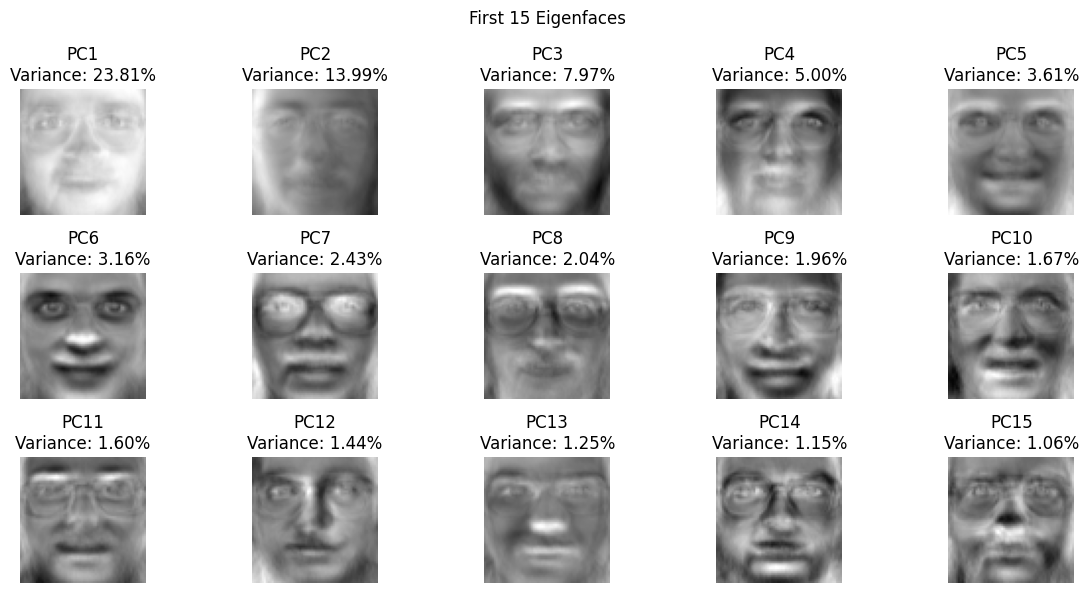

In [6]:
fig, axes = plt.subplots(3, 5, figsize = (12, 6))

for i, ax in enumerate(axes.flat):
  eigenface = pca_full.components_[i].reshape(64, 64)
  limit = np.max(np.abs(eigenface))
  ax.imshow(eigenface, cmap = 'gray', vmin = -limit, vmax = limit)
  ax.set_title(f'PC{i + 1}\nVariance: {explained_variance[i] * 100:.2f}%')
  ax.axis('off')

plt.suptitle('First 15 Eigenfaces')
plt.tight_layout()
plt.show()

**Task Five:**
*   Below, I will use a stratified 80/20 train-test split and compare logistic regression with all 4,096 features against a logistic regression model made from only the PCA features that retain 95 percent of the variance. To prevent data leakage, PCA is only fitted on the training data.
*   To compare them, I will contrast their accuracy and training time using bar plot just as I have in past assignments.



Raw Logistic: accuracy = 0.9625, fit time = 34.1164s
PCA Logistic: accuracy = 0.9625, fit time = 0.9596s
PCA Components retained: 111


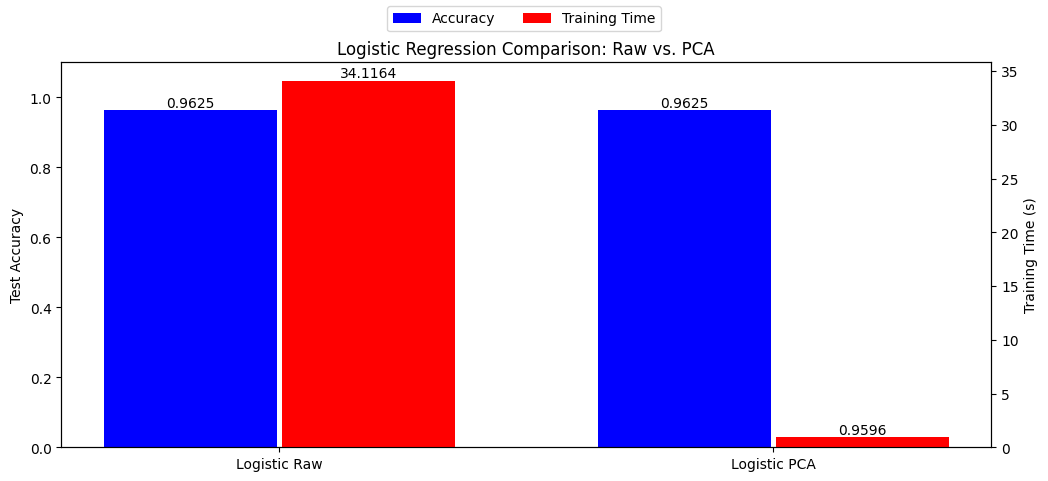

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 42)

log_raw = LogisticRegression(max_iter = 5000, solver = 'lbfgs', random_state = 42)

start = time.perf_counter()

log_raw.fit(X_train, y_train)

time_raw = time.perf_counter() - start
pred_raw = log_raw.predict(X_test)
acc_raw = accuracy_score(y_test, pred_raw)

pca_train = PCA(n_components = 0.95, svd_solver = 'full')

X_train_pca = pca_train.fit_transform(X_train)
X_test_pca = pca_train.transform(X_test)
log_pca = LogisticRegression(max_iter = 5000, solver = 'lbfgs', random_state = 42)

start = time.perf_counter()

log_pca.fit(X_train_pca, y_train)

time_pca = time.perf_counter() - start
pred_pca = log_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, pred_pca)

print(f'Raw Logistic: accuracy = {acc_raw:.4f}, fit time = {time_raw:.4f}s')
print(f'PCA Logistic: accuracy = {acc_pca:.4f}, fit time = {time_pca:.4f}s')
print('PCA Components retained:', pca_train.n_components_)

fig, ax1 = plt.subplots(figsize = (12, 5))
ax2 = ax1.twinx()

a = ax1.bar(np.arange(2) - 0.18, [acc_raw, acc_pca], 0.35, label = 'Accuracy', color = 'blue')
b = ax2.bar(np.arange(2) + 0.18, [time_raw, time_pca], 0.35, label = 'Training Time', color = 'red')

ax1.set_ylim(0, 1.1)
ax1.set_ylabel('Test Accuracy')
ax2.set_ylabel('Training Time (s)')
ax1.set_xticks(np.arange(2), ['Logistic Raw', 'Logistic PCA'])
ax1.bar_label(a, fmt = '%.4f')
ax2.bar_label(b, fmt = '%.4f')

fig.legend(loc = 'upper center', ncol = 2)

ax1.set_title('Logistic Regression Comparison: Raw vs. PCA')
plt.show()